# EDA — Valoración del terreno según su ubicación (Bogotá D.C.)

Análisis exploratorio de la capa catastral de construcciones. Todo el código
está desplegado en celdas para que puedas modificar cualquier detalle sin tocar
`src/`.

**Cómo usarlo**

- La celda de **parámetros editables** concentra paleta, tamaños de punto,
  cortes de anillos y zonas de validación. Cambia algo ahí y vuelve a ejecutar.
- Cada figura vive en su propia celda y es autocontenida: puedes reejecutar solo
  la que te interesa.
- `GUARDAR_FIGURAS = True` escribe los PNG a `outputs/figuras/` con los mismos
  nombres que usa el pipeline.

**Requiere** que las etapas 01 y 02 ya se hayan ejecutado (`python
run_pipeline.py --hasta 2`). La primera celda lo verifica y las lanza si faltan.

**Qué se está midiendo.** El archivo no trae avalúo ni precio, así que el
objetivo es un proxy explícito: el **IVS (Índice de Valor del Suelo)**, que
resume la intensidad edificatoria de cada manzana. La lógica es la teoría de la
renta del suelo: donde el suelo es caro, el mercado responde construyendo más
metros por metro de suelo.

## 0. Preparación

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial import cKDTree
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

%matplotlib inline

# la raiz del proyecto es la carpeta que contiene src/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import config as C          # rutas, geografia de referencia, listas de variables

print("raiz del proyecto:", ROOT)
print("sklearn/pandas listos |", "seaborn", sns.__version__)

raiz del proyecto: C:\Users\Usuario\Proyectos\Catastro_ML
sklearn/pandas listos | seaborn 0.12.1


In [2]:
# --- si faltan los datos procesados, se lanzan las etapas 01 y 02 ---
faltan = [p.name for p in (C.F_MUESTRA, C.F_DATASET, C.F_STATS) if not p.exists()]
if faltan:
    print("faltan:", faltan, "-> ejecutando etapas 01 y 02 (tarda ~2 min)")
    subprocess.run([sys.executable, str(ROOT / "run_pipeline.py"), "--hasta", "2"],
                   cwd=str(ROOT), check=True)
else:
    print("datos procesados disponibles")

datos procesados disponibles


### Parámetros editables

Todo lo que probablemente quieras ajustar está aquí.

In [3]:
# --- estilo ---
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 96, "savefig.dpi": 130, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
})

GUARDAR_FIGURAS = False        # True -> escribe los PNG en outputs/figuras/
RECALCULAR_IVS  = True         # True -> el indice se recalcula aqui (editable)

# --- paleta ---
COL_CLASE   = ["#4575b4", "#abd9e9", "#fdae61", "#d73027"]   # Bajo -> Alto
CMAP_VALOR  = "RdYlBu_r"       # mapa continuo del IVS
CMAP_DENS   = "viridis"        # densidades y conteos
VERDE, AZUL, NARANJA, ROJO, AMARILLO = "#2a9d8f", "#264653", "#f4a261", "#e76f51", "#e9c46a"

# --- mapas ---
TAM_PUNTO_MANZANA = 3.2        # tamano del punto en los mapas de manzanas
TAM_PUNTO_CONSTR  = 0.12       # tamano del punto en el mapa de construcciones
N_MUESTRA_MAPA    = 260_000    # construcciones dibujadas en el mapa
ASPECTO = 1 / np.cos(np.radians(4.65))   # correccion de latitud para Bogota

# --- analisis ---
BINS_ANILLO   = [0, 2, 4, 6, 8, 10, 13, 16, 20, 100]     # km al centro historico
ETIQ_ANILLO   = ["0-2","2-4","4-6","6-8","8-10","10-13","13-16","16-20","20+"]
K_VECINOS_MORAN = 8            # vecinos para la matriz de pesos espaciales
N_PERMUTACIONES = 99           # test de aleatorizacion de Moran
RADIO_ZONA_KM = 1.2            # radio de las zonas de validacion

# --- zonas conocidas para validar el indice (lon, lat) ---
ZONAS = {
    "Chico - Calle 93":             (-74.0470, 4.6760),
    "Salitre / Ciudad Empresarial": (-74.1050, 4.6570),
    "Chapinero - Calle 63":         (-74.0640, 4.6480),
    "Centro Internacional":         (-74.0680, 4.6150),
    "Usaquen":                      (-74.0310, 4.6950),
    "La Candelaria":                (-74.0730, 4.5960),
    "Suba centro":                  (-74.0830, 4.7440),
    "Kennedy":                      (-74.1500, 4.6280),
    "Bosa":                         (-74.1900, 4.6180),
    "Usme":                         (-74.1200, 4.5100),
}

def guardar(fig, nombre):
    "Guarda la figura si GUARDAR_FIGURAS esta activo."
    if GUARDAR_FIGURAS:
        fig.savefig(C.FIG_DIR / nombre, facecolor="white")
        print("guardada ->", nombre)

def formato_mapa(ax, titulo=None):
    "Encuadre urbano de Bogota; las manzanas rurales deformarian la escala."
    ax.set_xlim(*C.URB_LON); ax.set_ylim(*C.URB_LAT)
    ax.set_aspect(ASPECTO); ax.set_xlabel("longitud"); ax.grid(alpha=.25)
    if titulo:
        ax.set_title(titulo)

def recorte_urbano(d):
    return d[d["lon"].between(*C.URB_LON) & d["lat"].between(*C.URB_LAT)]

print("parametros cargados")

parametros cargados


## 1. Carga de los datos

Tres insumos, todos producidos por las etapas 01 y 02:

| Archivo | Nivel | Filas |
|---|---|---|
| `construcciones_muestra.csv.gz` | construcción individual | muestra del 15 % |
| `dataset_modelado.csv.gz` | manzana catastral | universo completo |
| `ingest_stats.json` | proceso de ingesta | contadores de calidad |

In [4]:
mues = pd.read_csv(C.F_MUESTRA, dtype={"lote": str, "manzana": str, "sector": str})
df   = pd.read_csv(C.F_DATASET, dtype={"manzana": str, "sector": str})
stats = json.loads(C.F_STATS.read_text(encoding="utf-8"))

df["valor_cat"] = pd.Categorical(df["valor_cat"], categories=C.CLASES, ordered=True)

# columnas derivadas que dependen de los parametros del notebook: se recalculan
# aqui para que un cambio en BINS_ANILLO o en el centro de referencia se propague
df["anillo_km"] = pd.cut(df["dist_centro_historico_km"], bins=BINS_ANILLO,
                         labels=ETIQ_ANILLO, ordered=True)
df["cuadrante"] = pd.cut(df["azimut"], bins=[-.01, 45, 135, 225, 315, 360.01],
                         labels=["Norte", "Oriente", "Sur", "Occidente", "Norte_"]
                         ).astype(str).replace({"Norte_": "Norte"})

print("construcciones (muestra): %d filas" % len(mues))
print("manzanas                : %d filas x %d columnas" % df.shape)
print("sectores catastrales    : %d" % df["sector"].nunique())
mues.head()

construcciones (muestra): 359395 filas
manzanas                : 38748 filas x 49 columnas
sectores catastrales    : 1140


,lote,manzana,sector,n_pisos,semisotanos,sotanos,mejora,voladizo,altura,elevacion,area_m2,perimetro_m,compacidad,lon,lat
0,005635042021,005635042,005635,1,0,0,0,1,1.0,1,4.80,12.74,0.3716,-74.112664,4.708066
1,002527014007,002527014,002527,3,0,0,0,0,0.0,3,55.95,29.99,0.7819,-74.107077,4.510249
2,008107013022,008107013,008107,1,0,0,0,0,0.0,1,56.40,31.69,0.7059,-74.068222,4.613721
3,002527007031,002527007,002527,1,0,0,0,0,0.0,1,24.00,22.00,0.6229,-74.108693,4.511263
4,002527016004,002527016,002527,1,0,0,0,0,0.0,1,10.03,14.03,0.6402,-74.107572,4.511123


In [5]:
# tipos, nulos y rango de cada variable de la tabla de manzanas
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "unicos": df.nunique(),
})
resumen.head(30)

,tipo,nulos,unicos
manzana,object,0,38748
sector,object,0,1140
n_construcciones,int64,0,410
n_lotes,int64,0,96
area_huella_m2,float64,0,37411
area_construida_m2,float64,0,38189
perimetro_total_m,float64,0,36394
pisos_prom,float64,0,7681
pisos_prom_pond,float64,0,19675
pisos_max,int64,0,41


## 2. Calidad del dato

Antes de interpretar nada, hay que saber qué sobrevivió a la ingesta y qué
atributos son realmente informativos.

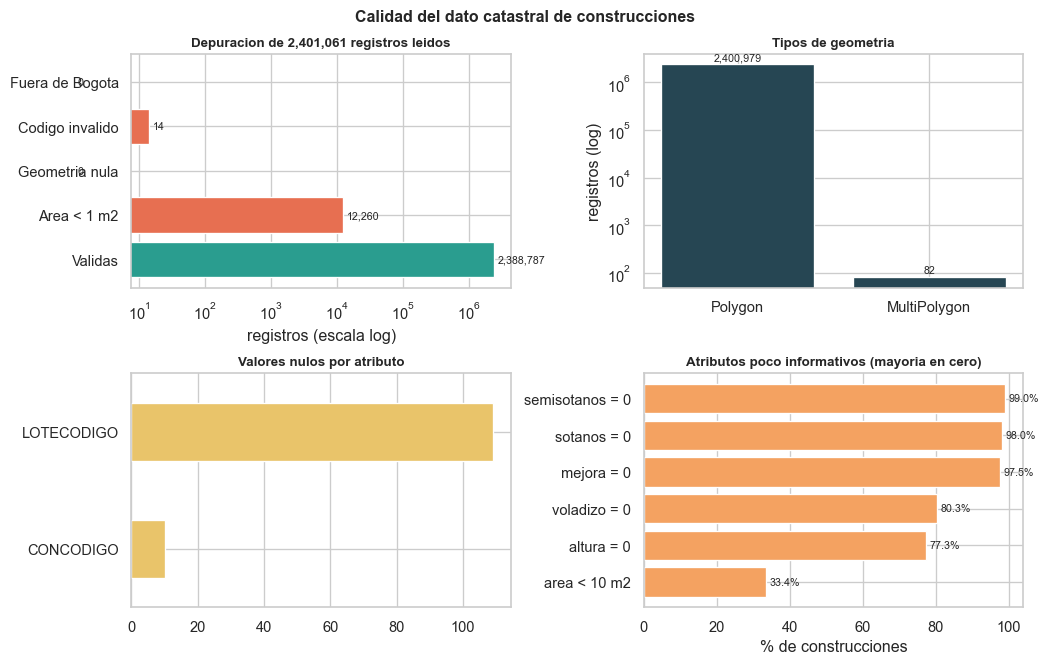

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# --- depuracion de registros ---
ax = axes[0, 0]
descartes = {
    "Validas":          stats["features_validas"],
    "Area < 1 m2":      stats["area_fuera_de_rango"],
    "Geometria nula":   stats["geometria_invalida"],
    "Codigo invalido":  stats["codigo_invalido"],
    "Fuera de Bogota":  stats["fuera_de_bbox"],
}
barras = ax.barh(list(descartes), list(descartes.values()),
                 color=[VERDE] + [ROJO] * 4)
ax.set_xscale("log")
ax.set_title("Depuracion de %s registros leidos" % f"{stats['features_leidas']:,}")
ax.set_xlabel("registros (escala log)")
for b, v in zip(barras, descartes.values()):
    ax.text(max(v, 1) * 1.15, b.get_y() + b.get_height() / 2, f"{v:,}",
            va="center", fontsize=8)

# --- tipos de geometria ---
ax = axes[0, 1]
tipos = pd.Series(stats["tipos_geometria"])
ax.bar(tipos.index, tipos.values, color=AZUL)
ax.set_yscale("log"); ax.set_title("Tipos de geometria"); ax.set_ylabel("registros (log)")
for i, v in enumerate(tipos.values):
    ax.text(i, v * 1.2, f"{v:,}", ha="center", fontsize=8)

# --- nulos ---
ax = axes[1, 0]
nulos = pd.Series(stats["nulos_por_campo"])
if len(nulos) == 0:
    ax.text(.5, .5, "Sin valores nulos\nen los atributos", ha="center",
            va="center", fontsize=12, color=VERDE)
    ax.set_axis_off()
else:
    nulos.sort_values().plot.barh(ax=ax, color=AMARILLO)
ax.set_title("Valores nulos por atributo")

# --- atributos poco informativos ---
ax = axes[1, 1]
ceros = pd.Series({
    "altura = 0":      (mues["altura"] == 0).mean(),
    "sotanos = 0":     (mues["sotanos"] == 0).mean(),
    "semisotanos = 0": (mues["semisotanos"] == 0).mean(),
    "mejora = 0":      (mues["mejora"] == 0).mean(),
    "voladizo = 0":    (mues["voladizo"] == 0).mean(),
    "area < 10 m2":    (mues["area_m2"] < 10).mean(),
}).sort_values()
ax.barh(ceros.index, ceros.values * 100, color=NARANJA)
ax.set_xlabel("% de construcciones")
ax.set_title("Atributos poco informativos (mayoria en cero)")
for i, v in enumerate(ceros.values):
    ax.text(v * 100 + 1, i, "%.1f%%" % (v * 100), va="center", fontsize=8)

fig.suptitle("Calidad del dato catastral de construcciones", fontsize=12, fontweight="bold")
fig.tight_layout()
guardar(fig, "fig01_calidad_datos.png")
plt.show()

Lo que hay que retener: **`CONALTURA` viene casi siempre en cero**, así que la
altura utilizable es `CONNPISOS`. Y una quinta parte de las huellas mide menos
de 4 m²: la capa descompone cada predio en partes homogéneas en altura, de modo
que los polígonos pequeños son legítimos, no ruido.

## 3. Distribuciones a nivel de construcción

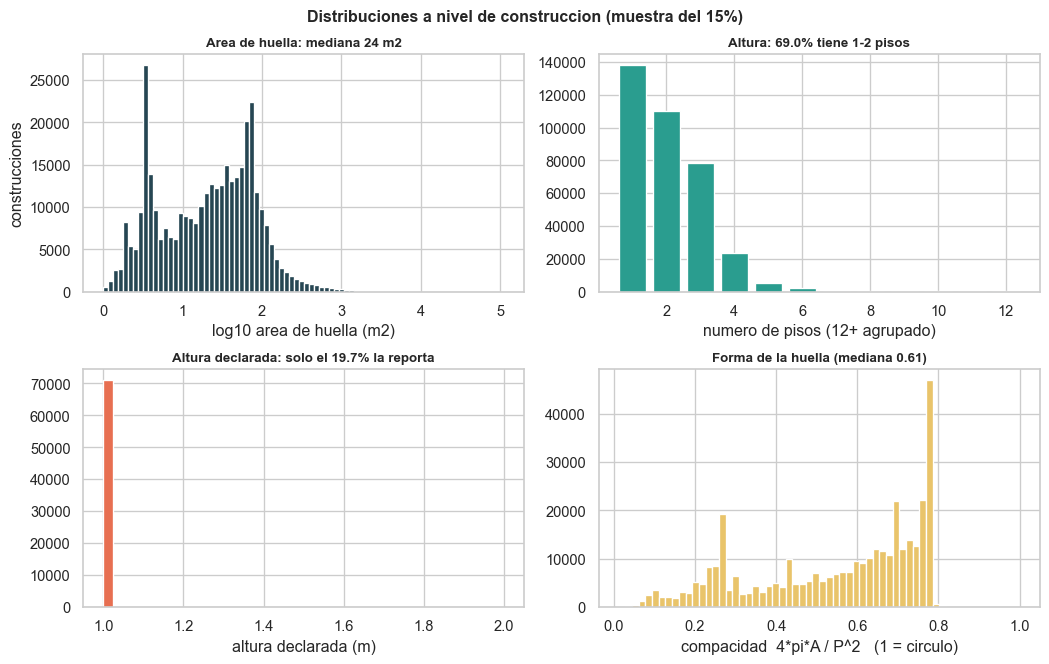

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

ax = axes[0, 0]
ax.hist(np.log10(mues["area_m2"].clip(lower=.1)), bins=80, color=AZUL)
ax.set_xlabel("log10 area de huella (m2)"); ax.set_ylabel("construcciones")
ax.set_title("Area de huella: mediana %.0f m2" % mues["area_m2"].median())

ax = axes[0, 1]
conteo = mues["n_pisos"].clip(upper=12).value_counts().sort_index()
ax.bar(conteo.index, conteo.values, color=VERDE)
ax.set_xlabel("numero de pisos (12+ agrupado)")
ax.set_title("Altura: %.1f%% tiene 1-2 pisos" % ((mues["n_pisos"] <= 2).mean() * 100))

ax = axes[1, 0]
ax.hist(mues.loc[mues["altura"] > 0, "altura"].clip(upper=20), bins=40, color=ROJO)
ax.set_xlabel("altura declarada (m)")
ax.set_title("Altura declarada: solo el %.1f%% la reporta"
             % ((mues["altura"] > 0).mean() * 100))

ax = axes[1, 1]
ax.hist(mues["compacidad"], bins=60, color=AMARILLO)
ax.set_xlabel("compacidad  4*pi*A / P^2   (1 = circulo)")
ax.set_title("Forma de la huella (mediana %.2f)" % mues["compacidad"].median())

fig.suptitle("Distribuciones a nivel de construccion (muestra del %.0f%%)"
             % (C.SAMPLE_FRAC * 100), fontsize=12, fontweight="bold")
fig.tight_layout()
guardar(fig, "fig02_distribuciones_construccion.png")
plt.show()

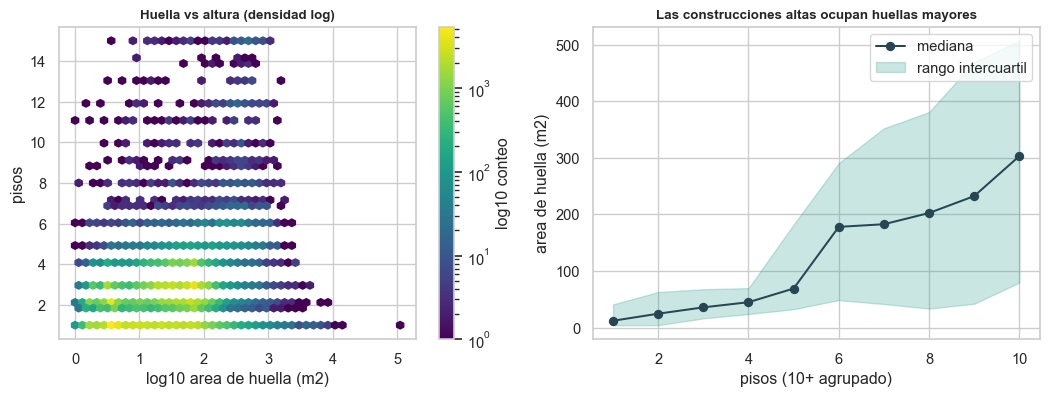

In [8]:
# relacion entre huella y altura
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
sub = mues.sample(min(120_000, len(mues)), random_state=C.SEED)
hb = ax.hexbin(np.log10(sub["area_m2"].clip(lower=.1)), sub["n_pisos"].clip(upper=15),
               gridsize=45, bins="log", cmap=CMAP_DENS, mincnt=1)
ax.set_xlabel("log10 area de huella (m2)"); ax.set_ylabel("pisos")
ax.set_title("Huella vs altura (densidad log)")
fig.colorbar(hb, ax=ax, label="log10 conteo")

ax = axes[1]
grp = mues.assign(pisos_g=mues["n_pisos"].clip(upper=10)).groupby("pisos_g")
med, q1, q3 = grp["area_m2"].median(), grp["area_m2"].quantile(.25), grp["area_m2"].quantile(.75)
ax.plot(med.index, med.values, "o-", color=AZUL, label="mediana")
ax.fill_between(med.index, q1.values, q3.values, alpha=.25, color=VERDE,
                label="rango intercuartil")
ax.set_xlabel("pisos (10+ agrupado)"); ax.set_ylabel("area de huella (m2)")
ax.set_title("Las construcciones altas ocupan huellas mayores"); ax.legend()

fig.tight_layout()
guardar(fig, "fig03_area_vs_pisos.png")
plt.show()

## 4. La ciudad construida

Primer vistazo espacial: dónde está la altura. Las manzanas rurales de Sumapaz
existen en el dato pero se dejan fuera del encuadre porque aplastarían la escala
del área urbana.

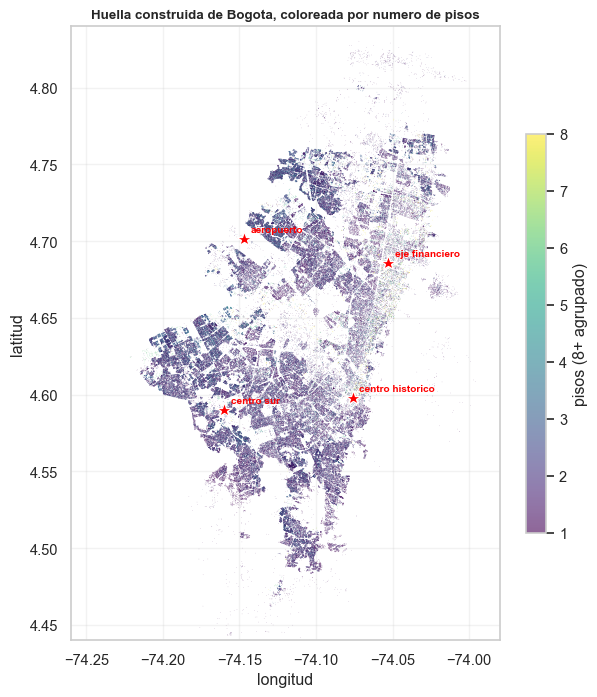

In [9]:
sub = recorte_urbano(mues).sample(min(N_MUESTRA_MAPA, len(recorte_urbano(mues))),
                                  random_state=C.SEED)

fig, ax = plt.subplots(figsize=(7.2, 9))
sc = ax.scatter(sub["lon"], sub["lat"], c=sub["n_pisos"].clip(upper=8),
                s=TAM_PUNTO_CONSTR, cmap=CMAP_DENS, alpha=.6, linewidths=0)
formato_mapa(ax, "Huella construida de Bogota, coloreada por numero de pisos")
ax.set_ylabel("latitud")
fig.colorbar(sc, ax=ax, label="pisos (8+ agrupado)", shrink=.6)

for nom, (lo, la) in C.PUNTOS_REFERENCIA.items():
    ax.plot(lo, la, "*", color="red", markersize=12, markeredgecolor="white")
    ax.annotate(nom.replace("_", " "), (lo, la), fontsize=7.5, color="red",
                fontweight="bold", xytext=(5, 5), textcoords="offset points")

guardar(fig, "fig04_mapa_construcciones_pisos.png")
plt.show()

## 5. El Índice de Valor del Suelo

No hay avalúo en el dato. El IVS resume la **intensidad edificatoria** de cada
manzana con cinco variables morfológicas, vía PCA sobre datos estandarizados.

Se retienen las componentes con **autovalor > 1** (criterio de Kaiser) y se
ponderan por su participación en la varianza explicada.

**Por qué no basta PC1.** PC1 mide intensidad bruta y confunde el barrio
informal autoconstruido (cobertura total del lote, 2-3 pisos, huellas de 30 m²,
sin sótanos) con el desarrollo formal en altura. PC2 es el eje que los separa:
carga positivo en tamaño de huella y sótanos. Si retienes solo PC1, Bosa y Usme
aparecen por encima de Chapinero.

> Para experimentar con el índice, cambia `COMPONENTES` o el criterio de
> retención en la celda siguiente y todo lo que sigue se recalcula.

In [10]:
COMPONENTES = list(C.COMPONENTES_IVS)   # <- edita esta lista para probar otro indice
print("componentes:", COMPONENTES)

X  = df[COMPONENTES].astype(float).values
Xs = StandardScaler().fit_transform(X)

pca    = PCA(n_components=len(COMPONENTES), random_state=C.SEED)
scores = pca.fit_transform(Xs)
var, autoval = pca.explained_variance_ratio_, pca.explained_variance_

N_RETENIDAS = max(int((autoval > 1.0).sum()), 1)     # criterio de Kaiser
anclas = ["pisos_prom_pond"] + ["log_huella_media"] * (len(COMPONENTES) - 1)
cargas = pca.components_.copy()
for j in range(N_RETENIDAS):                          # orientar el signo
    if np.corrcoef(scores[:, j], df[anclas[j]].values)[0, 1] < 0:
        scores[:, j] *= -1
        cargas[j]   *= -1

pesos = var[:N_RETENIDAS] / var[:N_RETENIDAS].sum()
compuesto = scores[:, :N_RETENIDAS] @ pesos

tabla_var = pd.DataFrame({
    "componente": ["PC%d" % (i + 1) for i in range(len(var))],
    "autovalor": autoval.round(4),
    "varianza_explicada": var.round(4),
    "varianza_acumulada": np.cumsum(var).round(4),
    "retenida": [i < N_RETENIDAS for i in range(len(var))],
    "peso_en_ivs": [round(pesos[i], 4) if i < N_RETENIDAS else 0. for i in range(len(var))],
})
tabla_cargas = pd.DataFrame(cargas[:N_RETENIDAS].T, index=COMPONENTES,
                            columns=["carga_pc%d" % (j + 1) for j in range(N_RETENIDAS)]).round(4)

if RECALCULAR_IVS:
    for j in range(N_RETENIDAS):
        df["pc%d" % (j + 1)] = scores[:, j]
    df["ivs"] = pd.Series(compuesto).rank(pct=True).values * 100
    df["ivs_zmean"] = pd.Series(Xs.mean(axis=1)).rank(pct=True).values * 100
    df["valor_cat"] = pd.qcut(df["ivs"], 4, labels=C.CLASES)
    df["valor_cod"] = df["valor_cat"].cat.codes
    df["alto_valor"] = (df["valor_cod"] == 3).astype(int)
    print("IVS recalculado en el notebook")

print("%d componentes retenidas, %.1f%% de la varianza" % (N_RETENIDAS, var[:N_RETENIDAS].sum() * 100))
print("concordancia con el promedio simple de z-scores: rho = %.3f"
      % df["ivs"].corr(df["ivs_zmean"], method="spearman"))
display(tabla_var)
tabla_cargas

componentes: ['log_indice_construccion', 'pisos_prom_pond', 'frac_pisos_ge3', 'frac_subterraneo', 'log_huella_media']
IVS recalculado en el notebook
2 componentes retenidas, 75.2% de la varianza
concordancia con el promedio simple de z-scores: rho = 0.968


,componente,autovalor,varianza_explicada,varianza_acumulada,retenida,peso_en_ivs
0,PC1,2.5042,0.5008,0.5008,True,0.6656
1,PC2,1.2581,0.2516,0.7525,True,0.3344
2,PC3,0.5587,0.1117,0.8642,False,0.0000
3,PC4,0.4234,0.0847,0.9489,False,0.0000
4,PC5,0.2557,0.0511,1.0000,False,0.0000


,carga_pc1,carga_pc2
log_indice_construccion,0.4824,-0.2275
pisos_prom_pond,0.5605,-0.1227
frac_pisos_ge3,0.4744,-0.4019
frac_subterraneo,0.4202,0.4823
log_huella_media,0.2269,0.7342


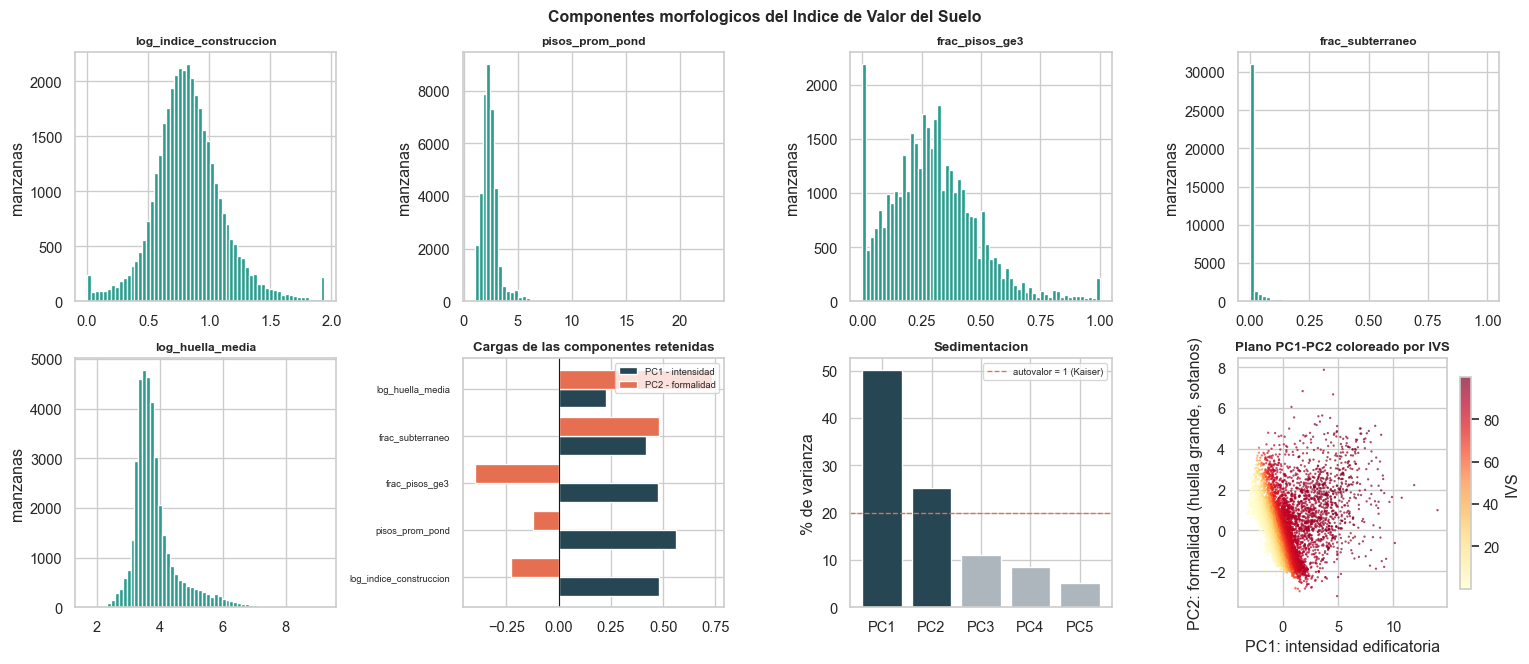

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
ejes = axes.ravel()

for ax, col in zip(ejes, COMPONENTES):
    ax.hist(df[col], bins=60, color=VERDE)
    ax.set_title(col, fontsize=9); ax.set_ylabel("manzanas")

ax = ejes[len(COMPONENTES)]
y = np.arange(len(tabla_cargas))
ax.barh(y - .2, tabla_cargas.iloc[:, 0], height=.4, color=AZUL, label="PC1 - intensidad")
if tabla_cargas.shape[1] > 1:
    ax.barh(y + .2, tabla_cargas.iloc[:, 1], height=.4, color=ROJO, label="PC2 - formalidad")
ax.set_yticks(y); ax.set_yticklabels(tabla_cargas.index, fontsize=7)
ax.axvline(0, color="k", lw=.8); ax.legend(fontsize=7)
ax.set_title("Cargas de las componentes retenidas")

ax = ejes[len(COMPONENTES) + 1]
ax.bar(tabla_var["componente"], tabla_var["varianza_explicada"] * 100,
       color=[AZUL if r else "#adb5bd" for r in tabla_var["retenida"]])
ax.axhline(100 / len(tabla_var), color=ROJO, ls="--", lw=1, label="autovalor = 1 (Kaiser)")
ax.set_ylabel("% de varianza"); ax.set_title("Sedimentacion"); ax.legend(fontsize=7)

ax = ejes[len(COMPONENTES) + 2]
smp = df.sample(min(12_000, len(df)), random_state=C.SEED)
sc = ax.scatter(smp["pc1"], smp["pc2"], c=smp["ivs"], s=3, cmap="YlOrRd", alpha=.7, linewidths=0)
ax.set_xlabel("PC1: intensidad edificatoria")
ax.set_ylabel("PC2: formalidad (huella grande, sotanos)")
ax.set_title("Plano PC1-PC2 coloreado por IVS")
fig.colorbar(sc, ax=ax, label="IVS", shrink=.85)

fig.suptitle("Componentes morfologicos del Indice de Valor del Suelo",
             fontsize=12, fontweight="bold")
fig.tight_layout()
guardar(fig, "fig05_componentes_ivs.png")
plt.show()

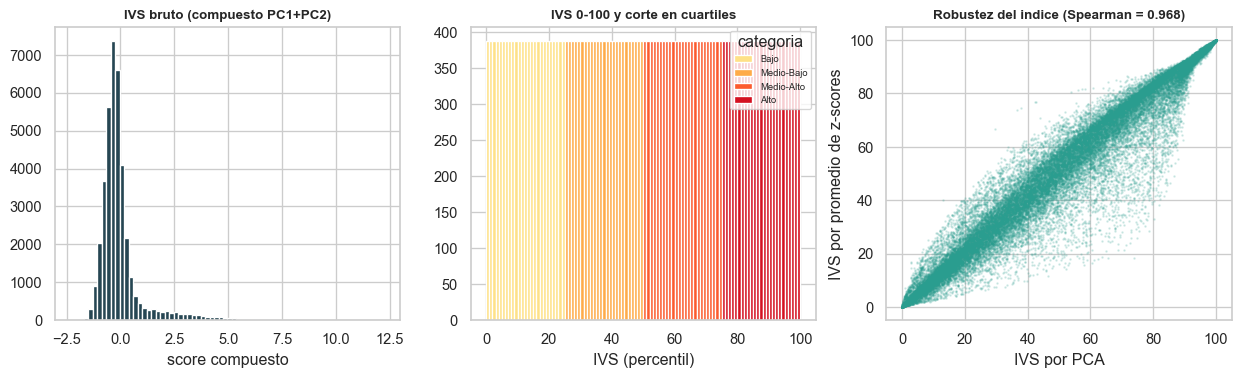

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

ax = axes[0]
ax.hist(compuesto, bins=70, color=AZUL)
ax.set_title("IVS bruto (compuesto PC1+PC2)"); ax.set_xlabel("score compuesto")

ax = axes[1]
colores = sns.color_palette("YlOrRd", 4)
for i, cl in enumerate(C.CLASES):
    ax.hist(df.loc[df["valor_cat"] == cl, "ivs"], bins=25, color=colores[i], label=cl)
ax.set_title("IVS 0-100 y corte en cuartiles"); ax.set_xlabel("IVS (percentil)")
ax.legend(title="categoria", fontsize=7)

ax = axes[2]
ax.scatter(df["ivs"], df["ivs_zmean"], s=1, alpha=.15, color=VERDE)
ax.set_xlabel("IVS por PCA"); ax.set_ylabel("IVS por promedio de z-scores")
ax.set_title("Robustez del indice (Spearman = %.3f)"
             % df["ivs"].corr(df["ivs_zmean"], method="spearman"))

fig.tight_layout()
guardar(fig, "fig06_ivs_distribucion.png")
plt.show()

### Validación externa del índice

Prueba de sentido común: el índice debería ordenar las zonas de Bogotá como lo
hace el mercado. Edita el diccionario `ZONAS` de la celda de parámetros para
añadir las que te interesen.

In [13]:
R_TIERRA_KM = 6371.0088

def haversine_km(lon, lat, lon0, lat0):
    p1, p2 = np.radians(lat), np.radians(lat0)
    h = (np.sin((p2 - p1) / 2) ** 2
         + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon0 - lon) / 2) ** 2)
    return 2 * R_TIERRA_KM * np.arcsin(np.sqrt(h))

filas = []
for nombre, (lo, la) in ZONAS.items():
    s = df[haversine_km(df["lon"].values, df["lat"].values, lo, la) < RADIO_ZONA_KM]
    if len(s) == 0:
        continue
    filas.append({
        "zona": nombre, "manzanas": len(s),
        "ivs_mediano": round(s["ivs"].median(), 1),
        "pisos_prom_pond": round(s["pisos_prom_pond"].median(), 2),
        "indice_construccion": round(s["indice_construccion"].median(), 2),
        "huella_media_m2": round(s["huella_media_m2"].median(), 1),
        "frac_subterraneo": round(s["frac_subterraneo"].median(), 2),
        "pct_alto_valor": round(s["alto_valor"].mean() * 100, 1),
    })

validacion = pd.DataFrame(filas).sort_values("ivs_mediano", ascending=False)
validacion.reset_index(drop=True)

,zona,manzanas,ivs_mediano,pisos_prom_pond,indice_construccion,huella_media_m2,frac_subterraneo,pct_alto_valor
0,Chico - Calle 93,277,97.1,4.39,2.66,144.4,0.52,96.8
1,Salitre / Ciudad Empresarial,114,96.0,2.72,1.80,260.9,0.26,63.2
2,Usaquen,250,92.0,2.92,1.60,105.6,0.27,75.6
3,Chapinero - Calle 63,484,86.9,2.69,1.70,70.7,0.06,68.2
4,Centro Internacional,318,83.5,2.61,1.45,76.3,0.03,67.0
5,Suba centro,289,64.1,2.33,1.05,45.8,0.00,37.0
6,La Candelaria,377,60.9,1.98,1.14,79.8,0.03,41.9
7,Usme,616,53.5,2.42,1.62,31.5,0.00,18.2
8,Bosa,1038,52.5,2.49,1.47,30.9,0.00,15.0
9,Kennedy,415,29.4,2.15,1.08,39.0,0.00,13.7


El orden del tramo alto coincide con el mercado real. El tramo bajo es más
ruidoso: los barrios informales densos alcanzan una intensidad edificatoria alta
que no corresponde a su precio, y PC2 corrige buena parte de ese sesgo pero no
todo. **La mitad inferior del ranking es menos confiable que la superior.**

## 6. Dónde está el valor

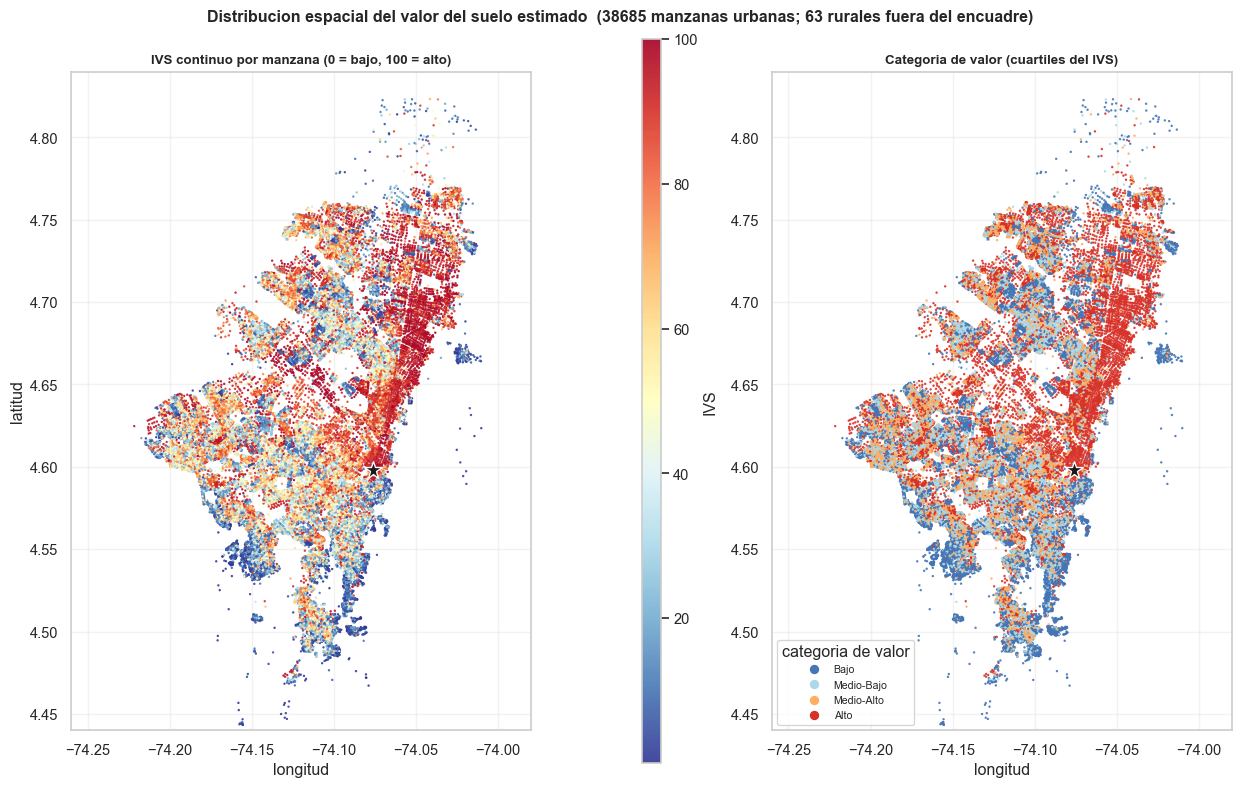

In [14]:
urb = recorte_urbano(df)
n_rural = len(df) - len(urb)

fig, axes = plt.subplots(1, 3, figsize=(13, 8.5),
                         gridspec_kw={"width_ratios": [1, .04, 1]})

ax = axes[0]
sc = ax.scatter(urb["lon"], urb["lat"], c=urb["ivs"], s=TAM_PUNTO_MANZANA,
                cmap=CMAP_VALOR, alpha=.9, linewidths=0)
formato_mapa(ax, "IVS continuo por manzana (0 = bajo, 100 = alto)")
fig.colorbar(sc, cax=axes[1], label="IVS"); axes[1].grid(False)
ax.set_ylabel("latitud")

ax = axes[2]
colores = dict(zip(C.CLASES, COL_CLASE))
mez = urb.sample(frac=1., random_state=C.SEED)      # evita que una clase tape a otra
ax.scatter(mez["lon"], mez["lat"], s=TAM_PUNTO_MANZANA, linewidths=0, alpha=.9,
           c=[colores[c] for c in mez["valor_cat"]])
handles = [plt.Line2D([], [], marker="o", ls="", color=colores[c], label=c) for c in C.CLASES]
ax.legend(handles=handles, title="categoria de valor", fontsize=8, loc="lower left")
formato_mapa(ax, "Categoria de valor (cuartiles del IVS)")

for a in (axes[0], axes[2]):
    a.plot(*C.CENTRO_HISTORICO, "k*", markersize=14, markeredgecolor="white")

fig.suptitle("Distribucion espacial del valor del suelo estimado  "
             "(%d manzanas urbanas; %d rurales fuera del encuadre)" % (len(urb), n_rural),
             fontsize=12, fontweight="bold")
fig.tight_layout()
guardar(fig, "fig07_mapa_ivs.png")
plt.show()

**El patrón es un corredor, no un círculo.** La franja de alto valor recorre el
borde oriental de sur a norte (centro internacional → Chapinero → Chicó →
Usaquén), con un núcleo secundario en Salitre. El sur y el suroccidente
concentran las manzanas de valor bajo.

## 7. Distancia contra dirección

La teoría clásica de la renta del suelo predice que el valor decae de forma
monótona al alejarse del centro. Vale la pena comprobar si Bogotá se comporta
así.

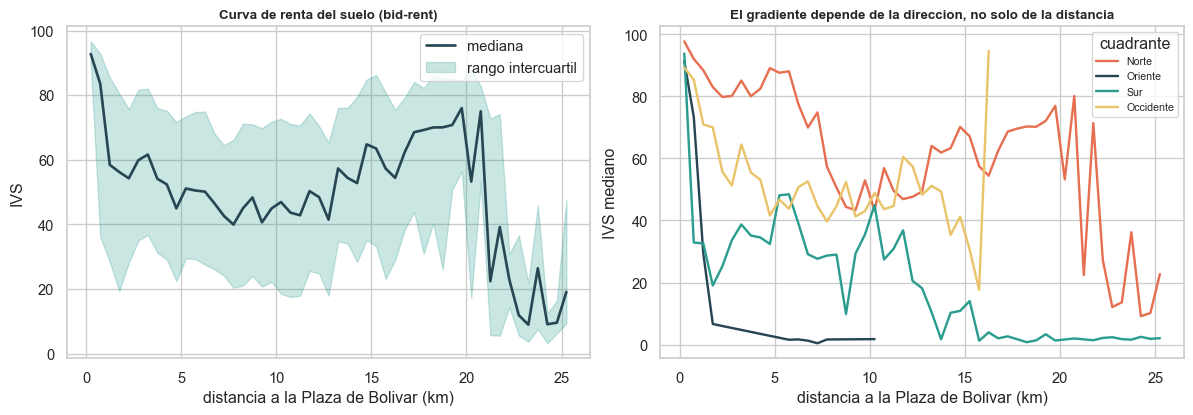

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
bins = np.arange(0, 26, .5)

ax = axes[0]
g = df.groupby(pd.cut(df["dist_centro_historico_km"], bins), observed=True)["ivs"]
centros = np.array([iv.mid for iv in g.median().index])
ax.plot(centros, g.median().values, "-", color=AZUL, lw=2, label="mediana")
ax.fill_between(centros, g.quantile(.25).values, g.quantile(.75).values,
                alpha=.25, color=VERDE, label="rango intercuartil")
ax.set_xlabel("distancia a la Plaza de Bolivar (km)"); ax.set_ylabel("IVS")
ax.set_title("Curva de renta del suelo (bid-rent)"); ax.legend()

ax = axes[1]
for cuad, color in zip(["Norte", "Oriente", "Sur", "Occidente"], [ROJO, AZUL, VERDE, AMARILLO]):
    s = df[df["cuadrante"] == cuad]
    gg = s.groupby(pd.cut(s["dist_centro_historico_km"], bins), observed=True)["ivs"].median()
    ax.plot([iv.mid for iv in gg.index], gg.values, "-", lw=1.8, color=color, label=cuad)
ax.set_xlabel("distancia a la Plaza de Bolivar (km)"); ax.set_ylabel("IVS mediano")
ax.set_title("El gradiente depende de la direccion, no solo de la distancia")
ax.legend(title="cuadrante", fontsize=8)

fig.tight_layout()
guardar(fig, "fig08_gradiente_distancia.png")
plt.show()

**La curva clásica no se cumple.** El IVS cae hasta los ~8 km y vuelve a subir en
los anillos exteriores del norte: Bogotá es policéntrica y su eje de valor migró
hacia el norte. La distancia sola no explica el valor; la dirección sí.

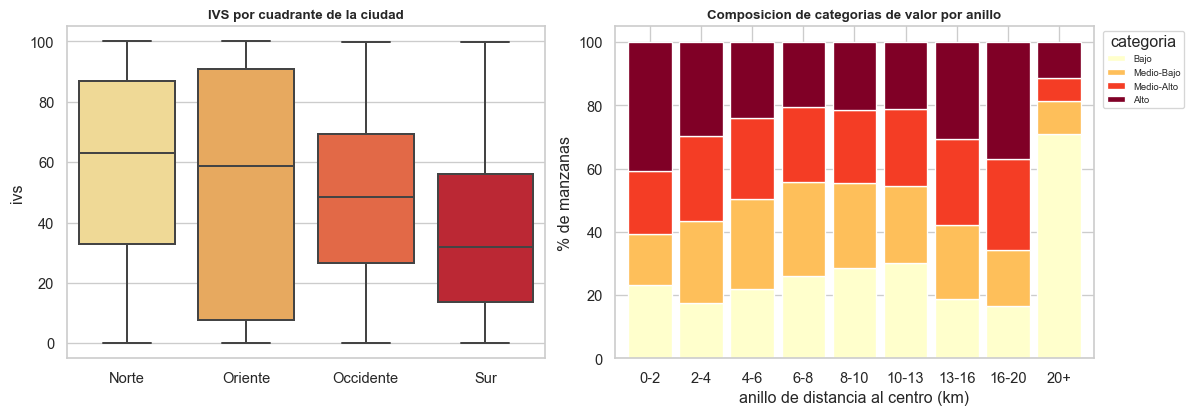

,manzanas,ivs_mediano,pisos_prom,indice_construccion,pct_alto_valor
anillo_km,,,,,
0-2,1106,64.24,2.50,1.17,40.6
2-4,2447,56.84,2.34,1.17,29.6
4-6,4239,49.67,2.39,1.28,24.0
6-8,4670,45.05,2.35,1.21,20.4
8-10,6368,44.64,2.43,1.25,21.6
10-13,11220,45.26,2.36,1.24,21.0
13-16,5651,57.40,2.73,1.31,30.5
16-20,2881,65.86,2.73,1.45,37.0
20+,166,8.20,1.44,0.02,11.4


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax = axes[0]
orden = df.groupby("cuadrante")["ivs"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="cuadrante", y="ivs", order=orden, ax=ax,
            showfliers=False, palette="YlOrRd")
ax.set_title("IVS por cuadrante de la ciudad"); ax.set_xlabel("")

ax = axes[1]
(pd.crosstab(df["anillo_km"], df["valor_cat"], normalize="index") * 100).plot.bar(
    stacked=True, ax=ax, colormap="YlOrRd", width=.85)
ax.set_xlabel("anillo de distancia al centro (km)"); ax.set_ylabel("% de manzanas")
ax.set_title("Composicion de categorias de valor por anillo")
ax.legend(title="categoria", fontsize=7, bbox_to_anchor=(1.01, 1))
ax.tick_params(axis="x", rotation=0)

fig.tight_layout()
guardar(fig, "fig09_ivs_por_cuadrante_y_anillo.png")
plt.show()

df.groupby("anillo_km", observed=True).agg(
    manzanas=("ivs", "size"), ivs_mediano=("ivs", "median"),
    pisos_prom=("pisos_prom_pond", "mean"),
    indice_construccion=("indice_construccion", "median"),
    pct_alto_valor=("alto_valor", lambda s: round(s.mean() * 100, 1)),
).round(2)

## 8. Qué variables de ubicación se asocian al valor

Correlación de Spearman (monótona, robusta a valores extremos) entre cada
variable de ubicación y el IVS.

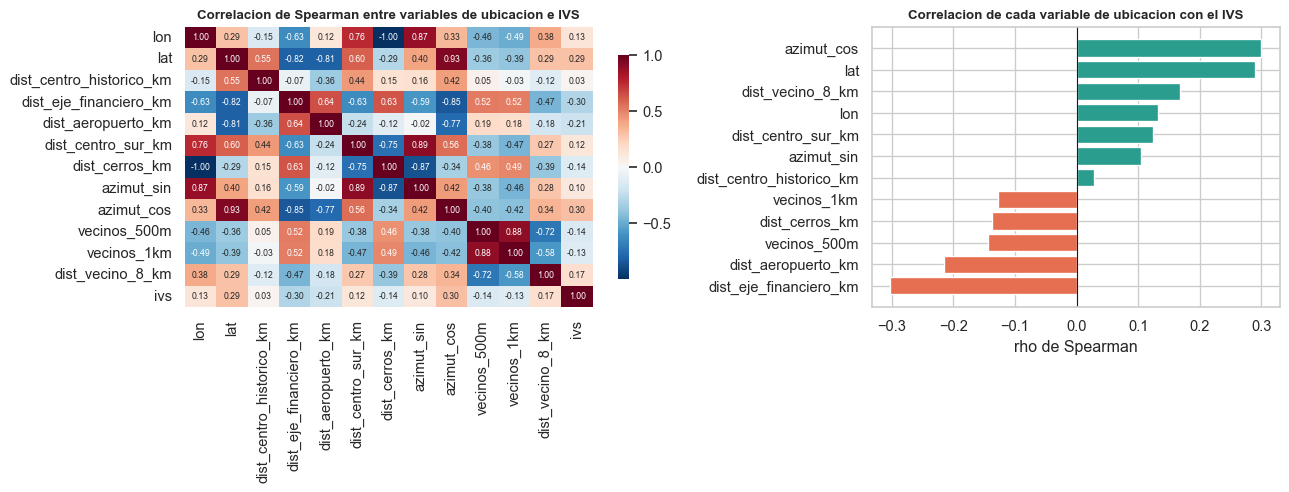

,|rho| con el IVS
dist_eje_financiero_km,0.303
azimut_cos,0.300
lat,0.290
dist_aeropuerto_km,0.215
dist_vecino_8_km,0.168
vecinos_500m,0.144
dist_cerros_km,0.137
lon,0.132
vecinos_1km,0.127
dist_centro_sur_km,0.124


In [17]:
cols = C.FEATURES_UBICACION + ["ivs"]
corr = df[cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0],
            annot_kws={"size": 6.5}, cbar_kws={"shrink": .8})
axes[0].set_title("Correlacion de Spearman entre variables de ubicacion e IVS")

s = corr["ivs"].drop("ivs").sort_values()
axes[1].barh(s.index, s.values, color=[ROJO if v < 0 else VERDE for v in s.values])
axes[1].axvline(0, color="k", lw=.8)
axes[1].set_title("Correlacion de cada variable de ubicacion con el IVS")
axes[1].set_xlabel("rho de Spearman")

fig.tight_layout()
guardar(fig, "fig10_correlaciones.png")
plt.show()

corr["ivs"].drop("ivs").abs().sort_values(ascending=False).round(3).to_frame("|rho| con el IVS")

Ojo con leer estas correlaciones de a una: las variables geográficas son
colineales por construcción (`dist_cerros_km` es casi una transformación lineal
de `lon`). Sirven para ver qué dimensiones importan, no para atribuir efectos.

## 9. Sectores catastrales extremos

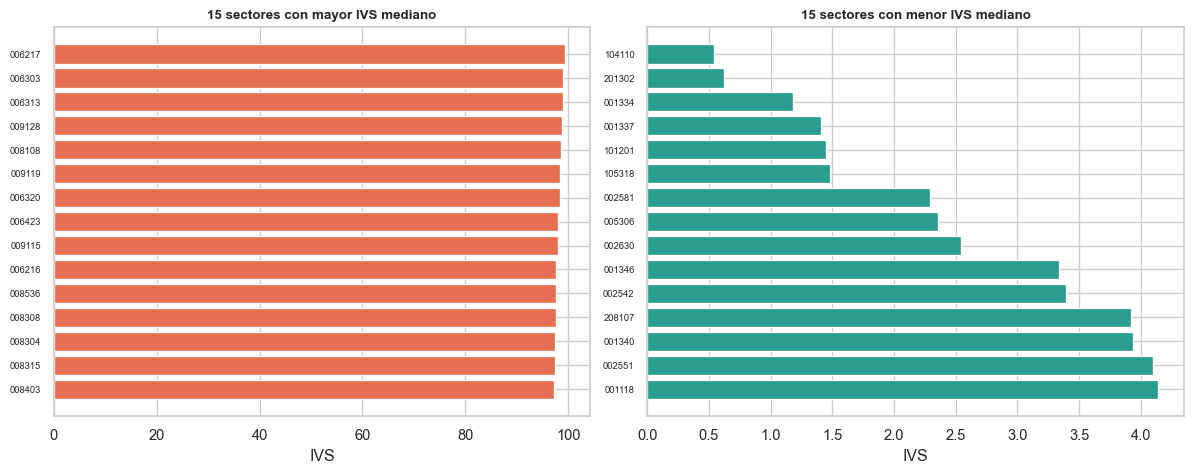

,manzanas,ivs,pisos,dist_centro,grupo
sector,,,,,
006217,30,99.30,5.04,5.83,alto
006303,20,99.04,5.98,7.75,alto
006313,29,98.96,4.22,7.04,alto
009128,27,98.74,4.36,15.69,alto
008108,13,98.54,7.55,2.52,alto
009119,11,98.37,4.64,14.79,alto
006320,24,98.31,5.71,8.91,alto
006423,21,98.11,3.70,10.09,alto
009115,24,98.06,3.77,14.40,alto


In [18]:
g = df.groupby("sector").agg(
    manzanas=("ivs", "size"), ivs=("ivs", "median"),
    pisos=("pisos_prom_pond", "mean"),
    dist_centro=("dist_centro_historico_km", "mean")).round(2)
g = g[g["manzanas"] >= 10]          # sectores con muestra suficiente
top, bot = g.nlargest(15, "ivs"), g.nsmallest(15, "ivs")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
axes[0].barh(top.index[::-1], top["ivs"][::-1], color=ROJO)
axes[0].set_title("15 sectores con mayor IVS mediano"); axes[0].set_xlabel("IVS")
axes[1].barh(bot.index[::-1], bot["ivs"][::-1], color=VERDE)
axes[1].set_title("15 sectores con menor IVS mediano"); axes[1].set_xlabel("IVS")
for ax in axes:
    ax.tick_params(axis="y", labelsize=7)

fig.tight_layout()
guardar(fig, "fig11_top_sectores.png")
plt.show()

pd.concat([top.assign(grupo="alto"), bot.assign(grupo="bajo")])

## 10. ¿El valor se agrupa en el espacio?

**Moran's I** mide autocorrelación espacial: si vale 0, el valor de una manzana
no dice nada del de sus vecinas; si es positivo, hay agrupamiento. La matriz de
pesos usa los `K_VECINOS_MORAN` vecinos más cercanos, estandarizada por filas, y
la significancia sale de un test de permutación.

Este resultado condiciona cualquier modelo posterior: con autocorrelación alta,
una partición aleatoria train/test deja manzanas de la misma cuadra a ambos
lados del corte e infla las métricas.

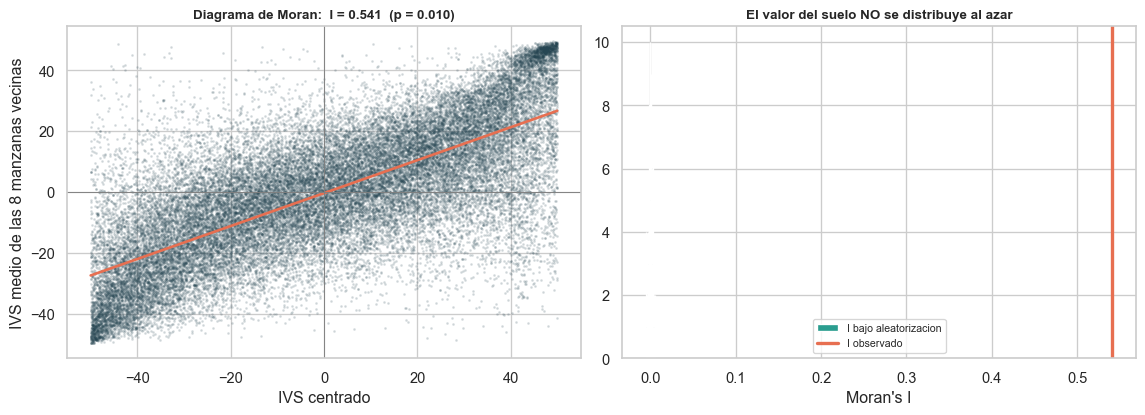

Moran's I = 0.5413   p = 0.0100   (8 vecinos, 99 permutaciones)


In [19]:
lon, lat = df["lon"].values, df["lat"].values
x, y = (lon - lon.mean()) * 110.9, (lat - lat.mean()) * 110.6   # km aproximados
tree = cKDTree(np.column_stack([x, y]))
_, idx = tree.query(np.column_stack([x, y]), k=K_VECINOS_MORAN + 1)
vecinos = idx[:, 1:]                                            # se excluye el propio punto

z = df["ivs"].values - df["ivs"].values.mean()
lag = z[vecinos].mean(axis=1)
I = float((z * lag).sum() / (z * z).sum())

rng = np.random.default_rng(C.SEED)
nulos = np.empty(N_PERMUTACIONES)
for i in range(N_PERMUTACIONES):
    zp = rng.permutation(z)
    nulos[i] = (zp * zp[vecinos].mean(axis=1)).sum() / (zp * zp).sum()
p_valor = (1 + (np.abs(nulos) >= abs(I)).sum()) / (N_PERMUTACIONES + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

ax = axes[0]
ax.scatter(z, lag, s=1.5, alpha=.12, color=AZUL)
b = np.polyfit(z, lag, 1)
xs = np.linspace(z.min(), z.max(), 50)
ax.plot(xs, np.polyval(b, xs), color=ROJO, lw=2)
ax.axhline(0, color="grey", lw=.7); ax.axvline(0, color="grey", lw=.7)
ax.set_xlabel("IVS centrado")
ax.set_ylabel("IVS medio de las %d manzanas vecinas" % K_VECINOS_MORAN)
ax.set_title("Diagrama de Moran:  I = %.3f  (p = %.3f)" % (I, p_valor))

ax = axes[1]
ax.hist(nulos, bins=25, color=VERDE, label="I bajo aleatorizacion")
ax.axvline(I, color=ROJO, lw=2.5, label="I observado")
ax.set_title("El valor del suelo NO se distribuye al azar")
ax.set_xlabel("Moran's I"); ax.legend(fontsize=8)

fig.tight_layout()
guardar(fig, "fig12_autocorrelacion_espacial.png")
plt.show()

print("Moran's I = %.4f   p = %.4f   (%d vecinos, %d permutaciones)"
      % (I, p_valor, K_VECINOS_MORAN, N_PERMUTACIONES))

## 11. Síntesis

1. **El dato es bueno pero parcial.** Casi sin nulos, con geometría válida en el
   99.5 % de los registros; a cambio, `CONALTURA`, `CONMEJORA` y `CONVOLADIZ`
   están casi siempre en cero. La información utilizable es pisos, huella y
   subterráneos.
2. **El valor del suelo se organiza en corredores**, no en anillos concéntricos.
   El eje de mayor intensidad edificatoria recorre el borde oriental hacia el
   norte, con un núcleo secundario en Salitre.
3. **La dirección pesa más que la distancia.** La curva de renta clásica no se
   cumple: el IVS cae hasta los ~8 km del centro histórico y vuelve a subir en el
   norte lejano.
4. **Hay fuerte autocorrelación espacial** (Moran's I ≈ 0.54). Cualquier modelo
   supervisado sobre estos datos tiene que validarse con particiones
   espaciales — por sector catastral — o sus métricas serán optimistas.
5. **El IVS es un proxy, no un avalúo.** Mide intensidad y formalidad
   constructiva. Para convertirlo en pesos por m² habría que cruzarlo con la base
   de avalúos catastrales o con ofertas de mercado.

El modelado supervisado que parte de estas conclusiones está en
`src/models.py` (siete clasificadores con validación espacial por sector).